# 서울시 무더위쉼터 EDA

기존 무더위쉼터와 60대 이상 유동인구가 어디에 얼마나 있는지, 둘이 어긋나는 곳이 어디인지 본다.
입지모형(`서울_입지분석.ipynb`)으로 넘어가기 전 단계다.

**지금 저장된 그림은 모의 유동인구로 그린 것이다.** 값이 난수라서 그림의 모양만 확인할 수 있고 해석하면 안 된다.
안심구역에서는 `0. 설정`의 `SAFE_ZONE`을 `True`로 바꾸고 그 아래 경로 세 줄을 확인한 뒤 다시 실행한다.
안심구역 유동인구는 7~9월을 합친 파일 하나다. 60대 이상 수요는 `weight` 열(9~18시)을 쓰며, 입지모형 노트북과 같은 값이다.
그림에는 제목을 넣지 않았다. 보고서에서 캡션으로 붙인다.

1. 자치구별 쉼터 수와 유동인구 (표, 산점도, 막대)
2. 60대 이상 유동인구 지도 (500m 구획, 상위 10곳 표시)
3. 사각지대 지도 (500m 구획, 상위 10곳 표시)와 자치구별 미커버 수요
4. 쉼터까지 거리 분포와 자치구별 커버율
5. 시간대별 유동인구와 쉼터 운영시간
6. 요일별 유동인구와 쉼터 개방
7. 쉼터 유형 구성
8. 자치구별 60대 이상 비율
9. 후보시설 현황

데이터 행을 그대로 출력하는 셀은 없다. 출력은 건수, 자치구 단위 집계, 그림뿐이다.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib import font_manager
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.spatial import cKDTree
from shapely.geometry import box

# 한글 글꼴. 설치된 것 중 먼저 찾은 것을 쓴다.
installed = {f.name for f in font_manager.fontManager.ttflist}
for font_name in ["Malgun Gothic", "NanumGothic", "NanumBarunGothic", "AppleGothic"]:
    if font_name in installed:
        plt.rcParams["font.family"] = font_name
        break
else:
    print("한글 글꼴을 찾지 못했다. 그림의 한글이 깨지면 font_name 목록에 설치된 글꼴 이름을 추가한다.")
plt.rcParams["axes.unicode_minus"] = False

# 색. 그림 전체에서 같은 역할에는 같은 색을 쓴다.
INK, INK_SUB, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
SURFACE, LAND, BORDER, GRID = "#fcfcfb", "#f3f2ee", "#c3c2b7", "#e1e0d9"
BLUE = "#2a78d6"     # 기본 계열
ORANGE = "#eb6834"   # 강조 (공급이 부족한 쪽)
GRAY = "#b5b3aa"     # 배경 역할
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#2a78d6", "#104281"]
ORANGE_RAMP = ["#f6bfa6", "#eb6834", "#a83c12"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BORDER, "axes.labelcolor": INK_SUB, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_SUB, "axes.titlelocation": "left",
})

## 0. 설정

In [2]:
SAFE_ZONE = False     # 데이터안심구역에서 실행할 때 True로 바꾼다

if SAFE_ZONE:
    # 안심구역 안의 경로. 실제 파일 이름과 다르면 이 세 줄만 고친다.
    FLOW_PATH = Path("upload/SeoulPopulation7to9.csv")   # 7~9월을 합친 서울 유동인구 (성별ㆍ연령, 시간대, 요일 병합)
    INPUT = Path("upload")            # 반입한 경계, 쉼터, 후보시설 파일
    OUT = Path("eda_output")          # 그림과 표가 저장될 폴더
else:
    # 로컬. 저장소 폴더 구조를 그대로 쓰고 유동인구는 세 파일을 병합해 둔 모의 자료를 읽는다.
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "2_데이터").exists())
    FLOW_PATH = ROOT / "2_데이터" / "모의_유동인구" / "seoul_flow_merged_202401.csv"
    INPUT = ROOT / "2_데이터" / "서울_모형입력"
    OUT = ROOT / "4_결과" / "서울_EDA"

# 60대 이상 수요. 안심구역 파일은 weight 열(9~18시 60대 이상, population 열과 같은 값)을 쓴다.
# 이 열이 없는 파일(로컬 모의 자료)은 AGE60_COLS를 더해 만든다. 입지모형 노트북과 같은 규칙이다.
WEIGHT_COL = "weight"

GU_PATH = INPUT / "SeoulBoundary.shp"
SHELTER_PATH = INPUT / "SeoulCoolingCenter.csv"
CANDIDATE_PATH = INPUT / "SeoulCandidateFacility.csv"

COVERAGE_DISTANCE_M = 219                  # 서울_입지분석.ipynb와 같은 값
DISTANCE_MARKS = [COVERAGE_DISTANCE_M, 300, 400]
PEAK_HOURS = (12, 17)                      # 폭염 시간대로 표시할 구간 (시 이상, 시 미만)
BLOCK_M = 500                              # 지도에서 격자를 묶는 구획 크기 (m)
TOP_N = 10                                 # 지도에 순위를 붙일 구획 수


AGE60_COLS = ["MAN_FLOW_POP_CNT_60GU", "WMAN_FLOW_POP_CNT_60GU"]
TIME_COLS = [f"THST_{h:02d}" for h in range(24)]
DAY_KEYS = ["MON", "TUE", "WED", "THU", "FRI", "SAT", "SUN"]
DAY_KO = ["월", "화", "수", "목", "금", "토", "일"]
DAY_COLS = [f"FLOW_POP_CNT_{d}" for d in DAY_KEYS]

SAVE = True
OUT.mkdir(parents=True, exist_ok=True)

# 파일이 제자리에 있는지 먼저 확인한다. 없는 파일이 있으면 여기서 멈춘다.
missing = [str(f) for f in (FLOW_PATH, GU_PATH, SHELTER_PATH, CANDIDATE_PATH) if not f.exists()]
if missing:
    raise FileNotFoundError("다음 파일을 찾을 수 없다: " + ", ".join(missing))
print("입력 파일 4개 확인")

입력 파일 4개 확인


## 0-1. 그림 보조 함수

In [3]:
def save(fig, name):
    if SAVE:
        fig.savefig(OUT / name, dpi=200, bbox_inches="tight")


def clean(ax, grid="x"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis=grid, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)


def barh(ax, values, highlight=None, fmt="{:,.0f}", avg=None, avg_label=None, labels=None):
    """가로 막대. values는 위에서 아래로 그릴 순서의 Series."""
    values = values.iloc[::-1]
    colors = [ORANGE if highlight is not None and k in highlight else BLUE for k in values.index]
    ax.barh(values.index, values.to_numpy(), color=colors, height=0.72)
    span = values.max()
    halo = [pe.withStroke(linewidth=2.5, foreground=SURFACE)]
    for y, (k, v) in enumerate(values.items()):
        text = labels[k] if labels is not None else fmt.format(v)
        ax.text(v + span * 0.01, y, text, va="center", fontsize=8.5, color=INK_SUB,
                path_effects=halo, zorder=5)
    if avg is not None:
        ax.axvline(avg, color=INK_SUB, linewidth=1, linestyle=(0, (4, 3)), zorder=4)
        ax.annotate(avg_label, (avg, 1), xycoords=("data", "axes fraction"), xytext=(5, -3),
                    textcoords="offset points", fontsize=9, color=INK_SUB, ha="left", va="top",
                    path_effects=halo, zorder=5)
    ax.set_ylim(-0.7, len(values) + (0.5 if avg is not None else -0.3))
    ax.set_xlim(0, span * 1.12)
    ax.spines["left"].set_visible(False)
    clean(ax, "x")


def legend_top(ax, handles):
    ax.legend(handles=handles, frameon=False, loc="lower right", bbox_to_anchor=(1, 1.0),
              ncol=len(handles), fontsize=9, labelcolor=INK_SUB, borderaxespad=0.2)


def label_points(ax, xs, ys, names, bold=(), fontsize=8.5):
    """점 옆에 이름을 붙인다. 여섯 자리 중 다른 이름, 다른 점과 가장 덜 겹치는 자리를 고른다."""
    ax.figure.canvas.draw()
    pts = ax.transData.transform(np.column_stack([xs, ys]))
    scale = ax.figure.dpi / 72
    px = fontsize * scale
    spots = [(8, 7, "left", "bottom"), (8, -7, "left", "top"), (-8, 7, "right", "bottom"),
             (-8, -7, "right", "top"), (0, 11, "center", "bottom"), (0, -11, "center", "top")]
    boxes = [(x - 7 * scale, y - 7 * scale, x + 7 * scale, y + 7 * scale) for x, y in pts]

    def overlap(a, b):
        w = min(a[2], b[2]) - max(a[0], b[0])
        h = min(a[3], b[3]) - max(a[1], b[1])
        return w * h if w > 0 and h > 0 else 0

    for (x, y), name in zip(pts, names):
        w, h = len(name) * px * 1.05, px * 1.35
        best = None
        for dx, dy, ha, va in spots:
            x0 = x + dx * scale - {"left": 0, "right": w, "center": w / 2}[ha]
            y0 = y + dy * scale - (0 if va == "bottom" else h)
            box = (x0, y0, x0 + w, y0 + h)
            cost = sum(overlap(box, b) for b in boxes)
            if best is None or cost < best[0]:
                best = (cost, dx, dy, ha, va, box)
        _, dx, dy, ha, va, box = best
        boxes.append(box)
        ax.annotate(name, ax.transData.inverted().transform((x, y)), xytext=(dx, dy),
                    textcoords="offset points", ha=ha, va=va, fontsize=fontsize,
                    color=INK if name in bold else INK_SUB,
                    fontweight="bold" if name in bold else "normal")


def base_map(ax):
    gu.plot(ax=ax, facecolor=LAND, edgecolor=BORDER, linewidth=0.6, zorder=1)
    ax.set_aspect("equal")
    ax.set_axis_off()


def rank_badges(ax, blocks):
    """구획 중심에 순위 번호를 붙인다. blocks는 순위대로 정렬된 GeoDataFrame."""
    blocks.boundary.plot(ax=ax, color=INK, linewidth=1.1, zorder=7)
    pts = blocks.representative_point()
    xy = np.column_stack([pts.x, pts.y]).astype(float)
    min_gap = BLOCK_M * 1.9   # 번호 원 지름보다 조금 크게
    for _ in range(30):       # 붙어 있는 구획의 번호는 서로 밀어낸다
        for i in range(len(xy)):
            for j in range(i + 1, len(xy)):
                d = xy[j] - xy[i]
                dist = np.hypot(*d)
                if dist < min_gap:
                    push = (d / dist if dist > 0 else np.array([1.0, 0.0])) * (min_gap - dist) / 2
                    xy[i] -= push
                    xy[j] += push
    for rank, (x, y) in enumerate(xy, start=1):
        ax.text(x, y, str(rank), fontsize=8, fontweight="bold", color=INK, ha="center",
                va="center", zorder=8,
                bbox=dict(boxstyle="circle,pad=0.25", facecolor="white", edgecolor=INK, linewidth=0.9))


def gu_labels(ax, halo=LAND):
    for name, pt in zip(gu["gu"], gu.representative_point()):
        ax.text(pt.x, pt.y, name, fontsize=7.5, color=INK_SUB, ha="center", va="center", zorder=6,
                path_effects=[pe.withStroke(linewidth=2.2, foreground=halo)])

## 0-2. 자료 불러오기

유동인구 파일 하나(성별ㆍ연령, 시간대, 요일이 이미 병합된 것)를 읽고, 격자와 쉼터, 후보시설에 자치구를 붙인다.
구분자(`,`, `|`)와 인코딩은 자동으로 판단한다. 이전 공간결합에서 남은 `index_right` 열은 지운다.

In [4]:
gu = gpd.read_file(GU_PATH).to_crs(5179).rename(columns={"SIGUNGU_NM": "gu"})[["gu", "geometry"]]


def with_gu(points):
    out = gpd.sjoin(points, gu, how="left", predicate="within")
    return out.drop(columns="index_right")


with open(FLOW_PATH, "rb") as f:
    header = f.readline().decode("utf-8", errors="ignore")
flow_sep = "|" if header.count("|") > header.count(",") else ","
try:
    flow = pd.read_csv(FLOW_PATH, sep=flow_sep, encoding="utf-8-sig", low_memory=False)
except UnicodeDecodeError:
    flow = pd.read_csv(FLOW_PATH, sep=flow_sep, encoding="cp949", low_memory=False)
cols = set(flow.columns)
flow = flow.drop(columns=[c for c in ("index_right", "index_left") if c in cols])   # 남아 있으면 sjoin이 멈춘다
if "STD_YM" in cols:
    print("STD_YM 값:", sorted(flow["STD_YM"].unique()), "(여러 달이면 모두 더해진다)")

AGE_ALL_COLS = [c for c in flow.columns if "_FLOW_POP_CNT_" in c]   # 성별ㆍ연령 열 (MAN_, WMAN_)
flow["pop_all"] = flow[AGE_ALL_COLS].sum(axis=1)       # 8절 고령 비율의 분모 (하루 전체)
flow["pop60_age"] = flow[AGE60_COLS].sum(axis=1)       # 8절 고령 비율의 분자 (하루 전체)
if WEIGHT_COL in cols:
    flow["pop60"] = pd.to_numeric(flow[WEIGHT_COL], errors="coerce").fillna(0)
    weight_source = f"{WEIGHT_COL} 열"
else:
    flow["pop60"] = flow["pop60_age"]
    weight_source = " + ".join(AGE60_COLS)
flow = gpd.GeoDataFrame(flow.drop(columns="geometry", errors="ignore"),   # 문자열 geometry 열은 버린다
                        geometry=gpd.points_from_xy(flow["X_COORD"], flow["Y_COORD"]), crs=5179)
n_raw = len(flow)
flow = with_gu(flow).dropna(subset=["gu"]).reset_index(drop=True)

shelter = pd.read_csv(SHELTER_PATH, encoding="cp949")
shelter = gpd.GeoDataFrame(
    shelter, geometry=gpd.points_from_xy(shelter["경도"], shelter["위도"]), crs=4326).to_crs(5179)
shelter = with_gu(shelter)

cand = pd.read_csv(CANDIDATE_PATH, encoding="utf-8-sig").dropna(subset=["경도", "위도"])
cand = gpd.GeoDataFrame(cand, geometry=gpd.points_from_xy(cand["경도"], cand["위도"]), crs=4326).to_crs(5179)
cand = with_gu(cand)

# 격자에서 가장 가까운 쉼터까지 직선거리. 보행 네트워크 거리는 서울_입지분석.ipynb에서 계산한다.
dist, _ = cKDTree(np.column_stack([shelter.geometry.x, shelter.geometry.y])).query(
    np.column_stack([flow.geometry.x, flow.geometry.y]))
flow["dist_m"] = dist
flow["uncovered60"] = flow["pop60"].where(flow["dist_m"] > COVERAGE_DISTANCE_M, 0)

# 50m 격자를 500m 구획으로 묶는다. 지도는 이 구획 단위로 그린다.
flow["bx"] = np.floor(flow["X_COORD"] / BLOCK_M).astype(int)
flow["by"] = np.floor(flow["Y_COORD"] / BLOCK_M).astype(int)
block = flow.groupby(["bx", "by"]).agg(
    pop60=("pop60", "sum"),
    uncovered60=("uncovered60", "sum"),
    gu=("gu", lambda g: g.mode().iat[0]),
).reset_index()
seoul = gu.geometry.union_all() if hasattr(gu.geometry, "union_all") else gu.geometry.unary_union
block = gpd.GeoDataFrame(block, crs=5179, geometry=[
    box(x * BLOCK_M, y * BLOCK_M, (x + 1) * BLOCK_M, (y + 1) * BLOCK_M).intersection(seoul)
    for x, y in zip(block["bx"], block["by"])])

print("유동인구 파일:", FLOW_PATH.name)
print("60대 이상 수요:", weight_source)
print("유동인구 격자:", f"{n_raw:,}개 중 서울 경계 안 {len(flow):,}개")
print("기존 쉼터:", f"{len(shelter):,}개 (자치구 미부여 {int(shelter['gu'].isna().sum())}개)")
print("후보시설:", f"{len(cand):,}개 (자치구 미부여 {int(cand['gu'].isna().sum())}개)")
print(f"{BLOCK_M}m 구획:", f"{len(block):,}개")

STD_YM 값: [np.int64(202401)] (여러 달이면 모두 더해진다)


유동인구 파일: seoul_flow_merged_202401.csv
60대 이상 수요: MAN_FLOW_POP_CNT_60GU + WMAN_FLOW_POP_CNT_60GU
유동인구 격자: 217,630개 중 서울 경계 안 206,828개
기존 쉼터: 4,092개 (자치구 미부여 0개)
후보시설: 1,143개 (자치구 미부여 1개)
500m 구획: 2,310개


## 1. 자치구별 쉼터 수와 유동인구

쉼터 수만 보면 큰 구가 많아 보인다. 60대 이상 유동인구 1만 명당 쉼터 수로 나눠야 수요에 비해 공급이 적은 구가 드러난다.

In [5]:
gu_tab = flow.groupby("gu").agg(
    격자수=("pop60", "size"),
    유동인구_전체=("pop_all", "sum"),
    유동인구_60대이상=("pop60", "sum"),
    유동인구_60대이상_전일=("pop60_age", "sum"),
)
gu_tab["쉼터수"] = shelter.groupby("gu").size()
gu_tab["후보시설수"] = cand.groupby("gu").size()
gu_tab[["쉼터수", "후보시설수"]] = gu_tab[["쉼터수", "후보시설수"]].fillna(0).astype(int)
gu_tab["60대이상_비율_pct"] = gu_tab["유동인구_60대이상_전일"] / gu_tab["유동인구_전체"] * 100
gu_tab["고령1만명당_쉼터"] = gu_tab["쉼터수"] / gu_tab["유동인구_60대이상"] * 10_000

seoul_ratio = gu_tab["쉼터수"].sum() / gu_tab["유동인구_60대이상"].sum() * 10_000
low5 = set(gu_tab["고령1만명당_쉼터"].nsmallest(5).index)

if SAVE:
    gu_tab.to_csv(OUT / "01_자치구별_쉼터와_유동인구.csv", encoding="utf-8-sig")

display(gu_tab.sort_values("고령1만명당_쉼터").style.format({
    "격자수": "{:,}", "유동인구_전체": "{:,.0f}", "유동인구_60대이상": "{:,.0f}",
    "60대이상_비율_pct": "{:.1f}", "고령1만명당_쉼터": "{:.1f}",
}))

,격자수,유동인구_전체,유동인구_60대이상,유동인구_60대이상_전일,쉼터수,후보시설수,60대이상_비율_pct,고령1만명당_쉼터
gu,,,,,,,,
강남구,"15,278","140,980","36,914",36913.720000,98,151,26.2,26.5
서초구,"15,234","132,373","34,804",34803.590000,145,78,26.3,41.7
마포구,"7,771","73,054","19,179",19178.700000,90,95,26.3,46.9
용산구,"8,328","71,573","18,858",18857.820000,101,37,26.3,53.6
광진구,"6,464","62,158","16,188",16188.460000,100,57,26.0,61.8
송파구,"13,070","121,955","31,870",31870.150000,206,52,26.1,64.6
강북구,"5,655","55,361","14,492",14492.340000,97,35,26.2,66.9
종로구,"7,214","63,934","16,836",16836.040000,116,19,26.3,68.9
동대문구,"5,707","59,092","15,388",15388.090000,107,62,26.0,69.5


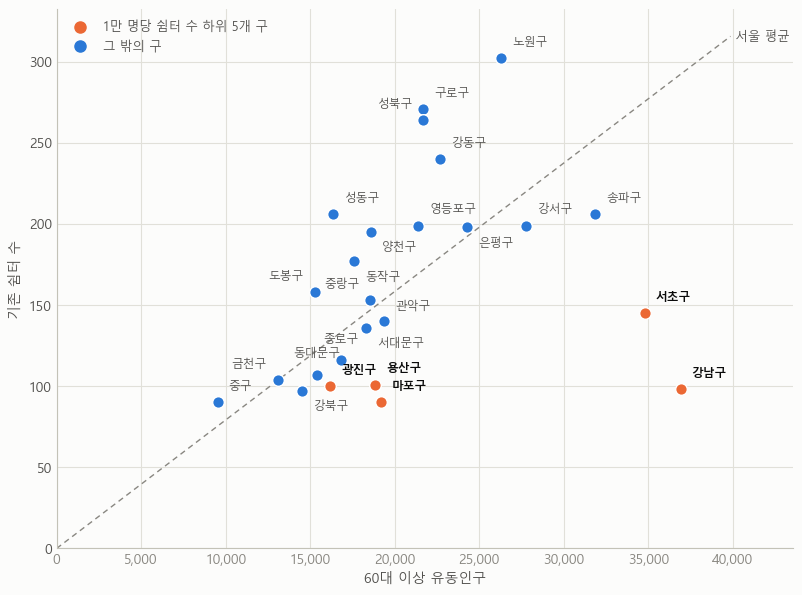

In [6]:
fig, ax = plt.subplots(figsize=(9.5, 7))

x, y = gu_tab["유동인구_60대이상"], gu_tab["쉼터수"]
is_low = gu_tab.index.isin(low5)
ax.scatter(x[~is_low], y[~is_low], s=70, color=BLUE, edgecolors="white", linewidths=1, zorder=3)
ax.scatter(x[is_low], y[is_low], s=70, color=ORANGE, edgecolors="white", linewidths=1, zorder=4)

# 서울 평균 비율선. 선 아래에 있으면 수요에 비해 쉼터가 적다.
xs = np.array([0, x.max() * 1.08])
ax.plot(xs, xs * seoul_ratio / 10_000, color=INK_MUTED, linewidth=1, linestyle=(0, (4, 3)), zorder=2)
ax.text(xs[1], xs[1] * seoul_ratio / 10_000, " 서울 평균", fontsize=9, color=INK_SUB, va="center")

ax.set_xlabel("60대 이상 유동인구")
ax.set_ylabel("기존 쉼터 수")
ax.set_xlim(0, x.max() * 1.18)
ax.set_ylim(0, y.max() * 1.1)
label_points(ax, x.to_numpy(), y.to_numpy(), list(gu_tab.index), bold=low5)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
clean(ax, "both")
ax.legend(handles=[
    Line2D([], [], marker="o", linestyle="", markersize=8, color=ORANGE, label="1만 명당 쉼터 수 하위 5개 구"),
    Line2D([], [], marker="o", linestyle="", markersize=8, color=BLUE, label="그 밖의 구"),
], frameon=False, loc="upper left", fontsize=9, labelcolor=INK_SUB)
save(fig, "01_수요와_공급_산점도.png")
plt.show()

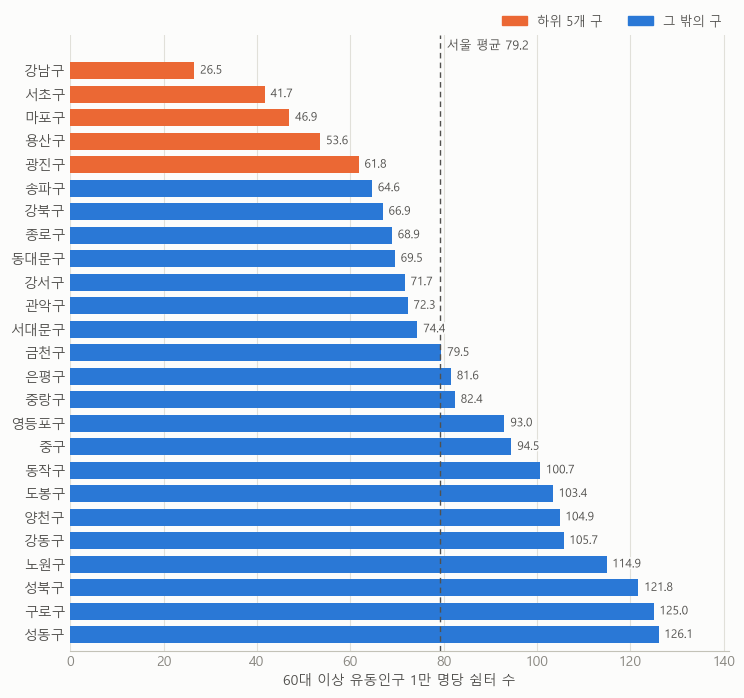

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 8))
barh(ax, gu_tab["고령1만명당_쉼터"].sort_values(), highlight=low5, fmt="{:.1f}",
     avg=seoul_ratio, avg_label=f"서울 평균 {seoul_ratio:.1f}")
legend_top(ax, [Patch(color=ORANGE, label="하위 5개 구"), Patch(color=BLUE, label="그 밖의 구")])
ax.set_xlabel("60대 이상 유동인구 1만 명당 쉼터 수")
save(fig, "01_고령1만명당_쉼터수.png")
plt.show()

## 2. 60대 이상 유동인구 지도

50m 격자 20만 개를 그대로 찍으면 점이 너무 잘아서 어디가 중요한지 보이지 않는다.
500m 구획으로 묶어 5분위 등급으로 칠하고, 60대 이상 유동인구가 가장 많은 구획 10곳에 순위를 붙인다.

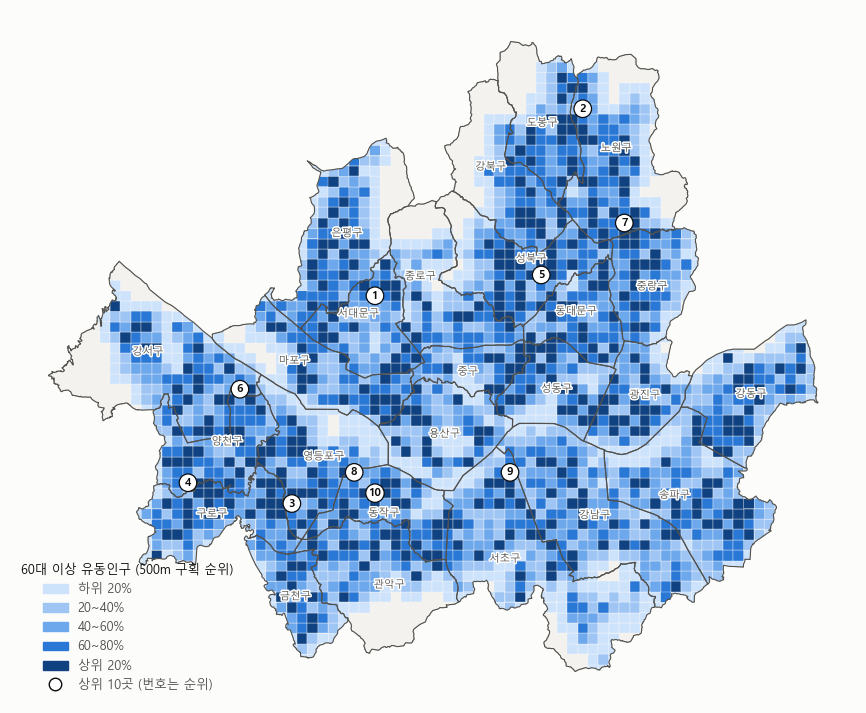

,자치구,60대이상_유동인구
순위,,
1,서대문구,497
2,노원구,477
3,영등포구,472
4,양천구,462
5,성북구,446
6,강서구,427
7,노원구,426
8,동작구,417
9,서초구,407


In [8]:
block["q5"] = pd.qcut(block["pop60"].rank(method="first"), 5, labels=False)
top_demand = block.nlargest(TOP_N, "pop60")

fig, ax = plt.subplots(figsize=(11, 9))
base_map(ax)
block.plot(ax=ax, color=[BLUE_RAMP[i] for i in block["q5"]], edgecolor=SURFACE, linewidth=0.25, zorder=2)
gu.boundary.plot(ax=ax, color=INK_SUB, linewidth=0.8, zorder=5)
gu_labels(ax, halo="white")
rank_badges(ax, top_demand)

labels = ["하위 20%", "20~40%", "40~60%", "60~80%", "상위 20%"]
handles = [Patch(color=c, label=l) for c, l in zip(BLUE_RAMP, labels)]
handles.append(Line2D([], [], marker="o", linestyle="", markersize=9, markerfacecolor="white",
                      markeredgecolor=INK, label=f"상위 {TOP_N}곳 (번호는 순위)"))
ax.legend(handles=handles, title=f"60대 이상 유동인구 ({BLOCK_M}m 구획 순위)", frameon=False,
          loc="lower left", fontsize=9, title_fontsize=9, labelcolor=INK_SUB)
save(fig, "02_고령유동인구_지도.png")
plt.show()

display(top_demand.assign(순위=range(1, TOP_N + 1))[["순위", "gu", "pop60"]]
        .rename(columns={"gu": "자치구", "pop60": "60대이상_유동인구"})
        .set_index("순위").style.format({"60대이상_유동인구": "{:,.0f}"}))

## 3. 사각지대 지도

구획마다 "기준거리 안에 쉼터가 없는 60대 이상 유동인구"를 더한다. 이 값이 큰 상위 20% 구획만 칠하고 나머지는 비워 둔다.
가장 큰 10곳에 순위를 붙였다. 신규 쉼터가 먼저 들어가야 할 자리의 후보다.
거리는 직선거리라서 실제 보행거리 기준보다 사각지대가 작게 잡힌다.

기준거리 219m 밖에 있는 60대 이상 유동인구: 36.0% (직선거리 기준)


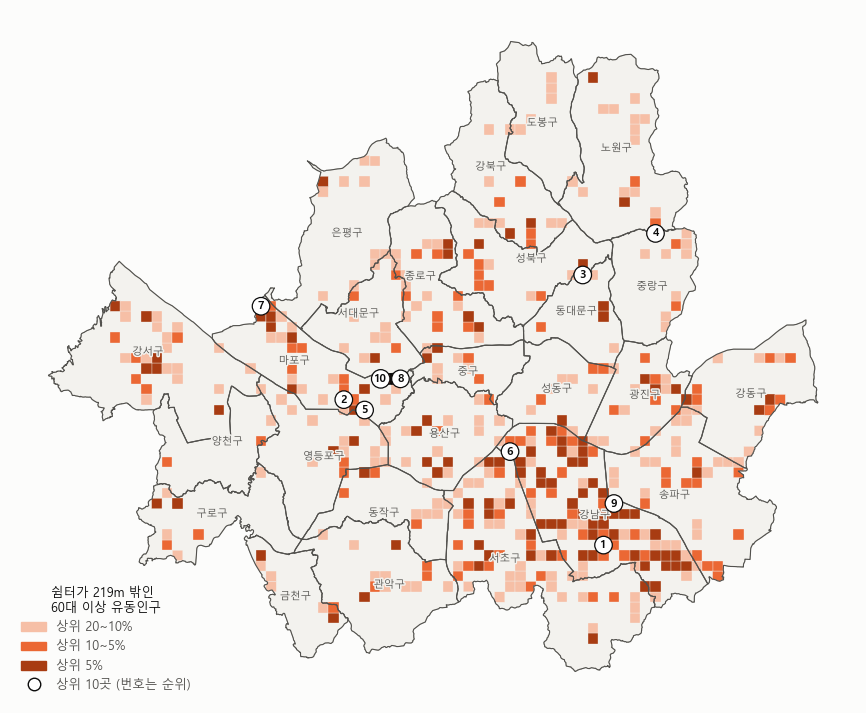

,자치구,미커버_60대이상,60대이상_유동인구
순위,,,
1,강남구,316,316
2,마포구,286,341
3,동대문구,281,281
4,중랑구,279,293
5,마포구,276,276
6,강남구,272,272
7,마포구,272,272
8,마포구,268,269
9,강남구,264,264


In [9]:
uncovered_share = flow["uncovered60"].sum() / flow["pop60"].sum() * 100
pct = block["uncovered60"].rank(pct=True)
block["gap_class"] = np.select([pct > 0.95, pct > 0.90, pct > 0.80], [2, 1, 0], default=-1)
gap_blocks = block[block["gap_class"] >= 0]
top_gap = block.nlargest(TOP_N, "uncovered60")

fig, ax = plt.subplots(figsize=(11, 9))
base_map(ax)
gap_blocks.plot(ax=ax, color=[ORANGE_RAMP[i] for i in gap_blocks["gap_class"]],
                edgecolor=LAND, linewidth=0.25, zorder=2)
gu.boundary.plot(ax=ax, color=INK_SUB, linewidth=0.8, zorder=5)
gu_labels(ax)
rank_badges(ax, top_gap)

labels = ["상위 20~10%", "상위 10~5%", "상위 5%"]
handles = [Patch(color=c, label=l) for c, l in zip(ORANGE_RAMP, labels)]
handles.append(Line2D([], [], marker="o", linestyle="", markersize=9, markerfacecolor="white",
                      markeredgecolor=INK, label=f"상위 {TOP_N}곳 (번호는 순위)"))
ax.legend(handles=handles, title=f"쉼터가 {COVERAGE_DISTANCE_M}m 밖인\n60대 이상 유동인구",
          frameon=False, loc="lower left", fontsize=9, title_fontsize=9, labelcolor=INK_SUB)
print(f"기준거리 {COVERAGE_DISTANCE_M}m 밖에 있는 60대 이상 유동인구: {uncovered_share:.1f}% (직선거리 기준)")
save(fig, "03_사각지대_지도.png")
plt.show()

display(top_gap.assign(순위=range(1, TOP_N + 1))[["순위", "gu", "uncovered60", "pop60"]]
        .rename(columns={"gu": "자치구", "uncovered60": "미커버_60대이상", "pop60": "60대이상_유동인구"})
        .set_index("순위").style.format({"미커버_60대이상": "{:,.0f}", "60대이상_유동인구": "{:,.0f}"}))

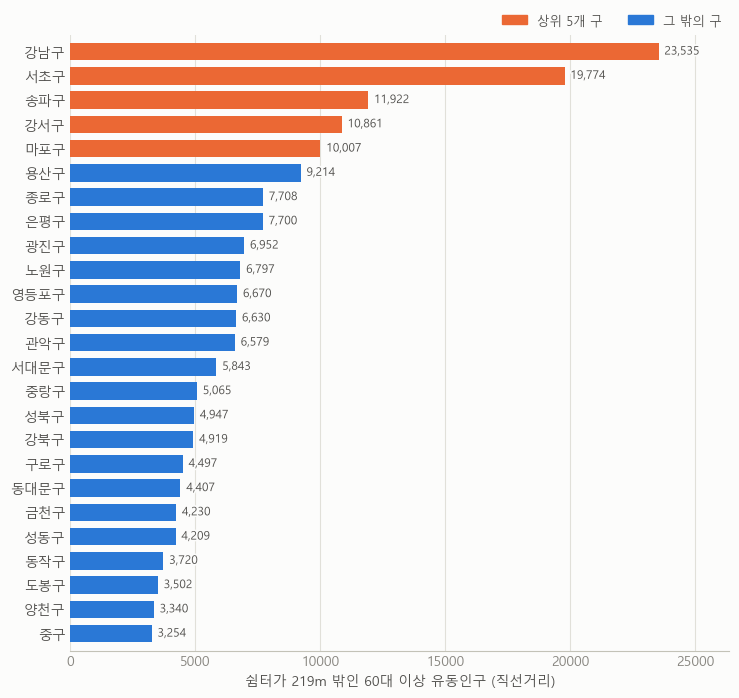

In [10]:
gu_tab["미커버_60대이상"] = flow.groupby("gu")["uncovered60"].sum()
top5_gap = set(gu_tab["미커버_60대이상"].nlargest(5).index)

fig, ax = plt.subplots(figsize=(8.5, 8))
barh(ax, gu_tab["미커버_60대이상"].sort_values(ascending=False), highlight=top5_gap, fmt="{:,.0f}")
legend_top(ax, [Patch(color=ORANGE, label="상위 5개 구"), Patch(color=BLUE, label="그 밖의 구")])
ax.set_xlabel(f"쉼터가 {COVERAGE_DISTANCE_M}m 밖인 60대 이상 유동인구 (직선거리)")
save(fig, "03_자치구별_미커버수요.png")
plt.show()

## 4. 쉼터까지 거리 분포와 자치구별 커버율

기준거리를 얼마로 잡느냐에 따라 커버율이 어떻게 달라지는지 본다. 기준거리를 정하는 근거 자료로 쓴다.

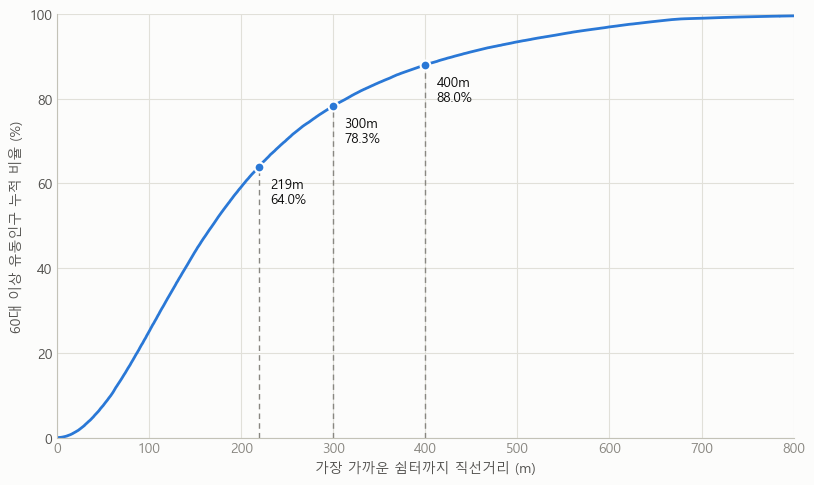

In [11]:
order = np.argsort(flow["dist_m"].to_numpy())
d_sorted = flow["dist_m"].to_numpy()[order]
cum = np.cumsum(flow["pop60"].to_numpy()[order]) / flow["pop60"].sum() * 100

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.plot(d_sorted, cum, color=BLUE, linewidth=2)
for d in DISTANCE_MARKS:
    pct = np.interp(d, d_sorted, cum)
    ax.plot([d, d], [0, pct], color=INK_MUTED, linewidth=1, linestyle=(0, (4, 3)))
    ax.scatter([d], [pct], s=50, color=BLUE, edgecolors="white", linewidths=1.5, zorder=3)
    ax.annotate(f"{d}m\n{pct:.1f}%", (d, pct), xytext=(8, -26), textcoords="offset points",
                fontsize=9.5, color=INK)
ax.set_xlim(0, 800)
ax.set_ylim(0, 100)
ax.set_xlabel("가장 가까운 쉼터까지 직선거리 (m)")
ax.set_ylabel("60대 이상 유동인구 누적 비율 (%)")
clean(ax, "both")
save(fig, "04_거리_누적분포.png")
plt.show()

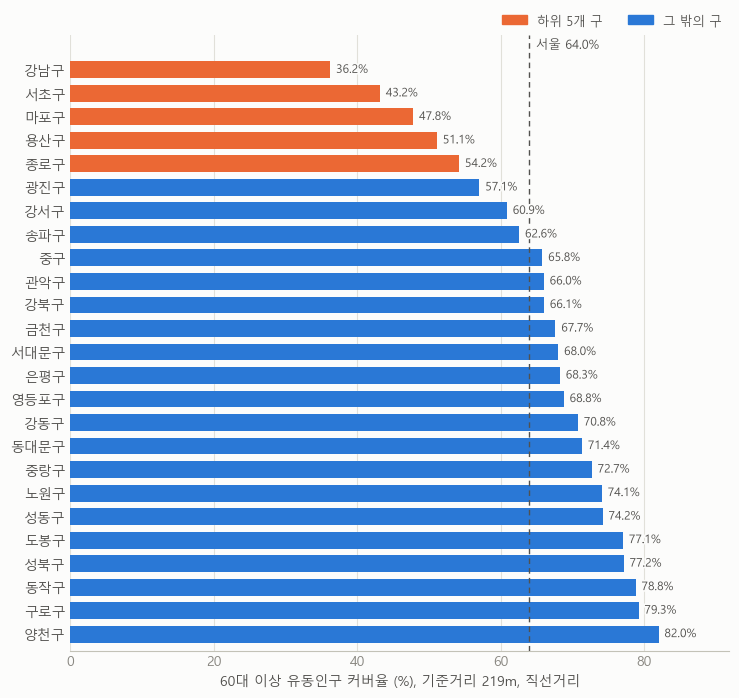

In [12]:
covered = flow["pop60"].where(flow["dist_m"] <= COVERAGE_DISTANCE_M, 0).groupby(flow["gu"]).sum()
gu_tab["커버율_pct"] = covered / gu_tab["유동인구_60대이상"] * 100
seoul_cov = covered.sum() / gu_tab["유동인구_60대이상"].sum() * 100
low5_cov = set(gu_tab["커버율_pct"].nsmallest(5).index)

fig, ax = plt.subplots(figsize=(8.5, 8))
barh(ax, gu_tab["커버율_pct"].sort_values(), highlight=low5_cov, fmt="{:.1f}%",
     avg=seoul_cov, avg_label=f"서울 {seoul_cov:.1f}%")
legend_top(ax, [Patch(color=ORANGE, label="하위 5개 구"), Patch(color=BLUE, label="그 밖의 구")])
ax.set_xlabel(f"60대 이상 유동인구 커버율 (%), 기준거리 {COVERAGE_DISTANCE_M}m, 직선거리")
save(fig, "04_자치구별_커버율.png")
plt.show()

## 5. 시간대별 유동인구와 쉼터 운영시간

사람이 가장 많은 시간에 쉼터가 열려 있는지 본다. 단위가 다른 두 값이라 한 축에 겹치지 않고 위아래로 나눠 그린다.
시간대 열(`THST_00`~`THST_23`)은 전체 연령 합계다. 60대 이상만의 시간대 분포는 자료에 없다.

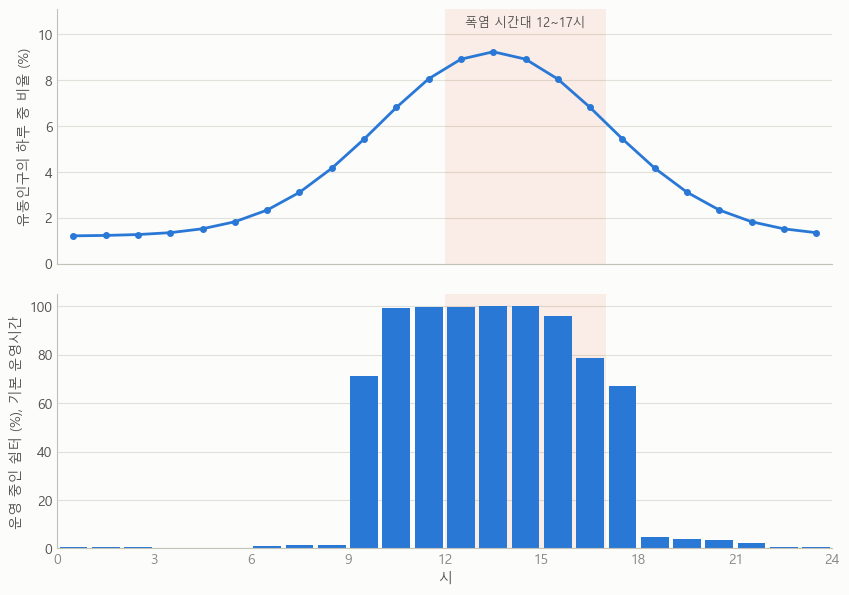

In [13]:
hours = np.arange(24)
hour_share = flow[TIME_COLS].sum().to_numpy()
hour_share = hour_share / hour_share.sum() * 100


def to_hour(col):
    return pd.to_numeric(shelter[col].astype(str).str.slice(0, 2), errors="coerce")


start, end = to_hour("기본운영_시작시간"), to_hour("기본운영_종료시간")


def open_at(h):
    same_day = (start <= h) & (h < end)
    overnight = (end <= start) & ((h >= start) | (h < end))
    return (same_day | overnight).mean() * 100


open_share = np.array([open_at(h) for h in hours])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"hspace": 0.12})
for ax in (ax1, ax2):
    ax.axvspan(PEAK_HOURS[0], PEAK_HOURS[1], color=ORANGE, alpha=0.10, linewidth=0)
    clean(ax, "y")

ax1.plot(hours + 0.5, hour_share, color=BLUE, linewidth=2, marker="o", markersize=4)
ax1.set_ylim(0, hour_share.max() * 1.2)
ax1.set_ylabel("유동인구의 하루 중 비율 (%)")
ax1.text(np.mean(PEAK_HOURS), hour_share.max() * 1.12, f"폭염 시간대 {PEAK_HOURS[0]}~{PEAK_HOURS[1]}시",
         ha="center", fontsize=9, color=INK_SUB)

ax2.bar(hours + 0.5, open_share, width=0.86, color=BLUE)
ax2.set_ylim(0, 105)
ax2.set_ylabel("운영 중인 쉼터 (%), 기본 운영시간")
ax2.set_xlabel("시")
ax2.set_xticks(np.arange(0, 25, 3))
ax2.set_xlim(0, 24)
save(fig, "05_시간대별_유동인구와_운영시간.png")
plt.show()

## 6. 요일별 유동인구와 쉼터 개방

주말에도 사람은 있는데 쉼터가 닫는지 본다. 개방 요일은 기본, 연장, 추가 운영 요일을 합친 것이다.

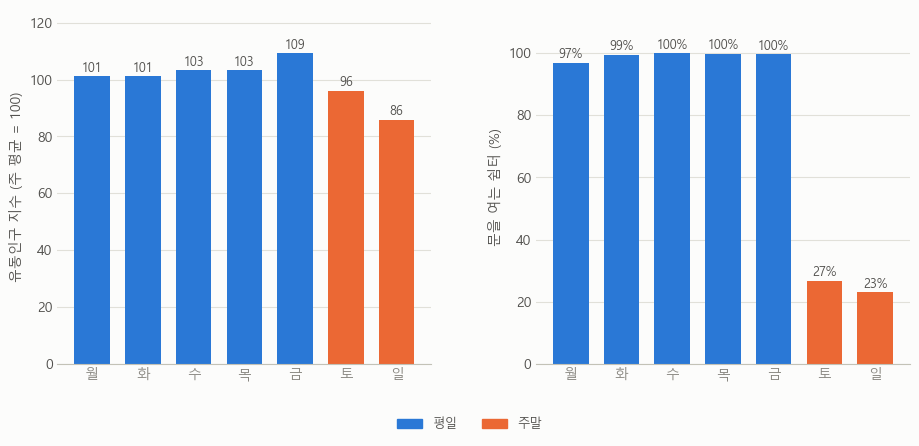

In [14]:
day_total = flow[DAY_COLS].sum().to_numpy()
day_index = day_total / day_total.mean() * 100


def day_text(col, flag=None):
    s = shelter[col].fillna("").astype(str)
    return s.where(shelter[flag].eq("Y"), "") if flag else s


open_days = (day_text("기본운영_요일") + "," + day_text("연장운영_요일", "연장운영_운영여부")
             + "," + day_text("추가운영_요일", "추가운영_운영여부"))
day_open = np.array([open_days.str.contains(d).mean() * 100 for d in DAY_KO])
weekend = [BLUE] * 5 + [ORANGE] * 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"wspace": 0.28})
for ax, vals, fmt in ((ax1, day_index, "{:.0f}"), (ax2, day_open, "{:.0f}%")):
    ax.bar(DAY_KO, vals, color=weekend, width=0.7)
    for i, v in enumerate(vals):
        ax.text(i, v + vals.max() * 0.015, fmt.format(v), ha="center", fontsize=9, color=INK_SUB)
    ax.set_ylim(0, vals.max() * 1.14)
    ax.spines["left"].set_visible(False)
    clean(ax, "y")
ax1.set_ylabel("유동인구 지수 (주 평균 = 100)")
ax2.set_ylabel("문을 여는 쉼터 (%)")
fig.legend(handles=[Patch(color=BLUE, label="평일"), Patch(color=ORANGE, label="주말")],
           frameon=False, loc="lower center", ncol=2, fontsize=9, labelcolor=INK_SUB,
           bbox_to_anchor=(0.5, -0.06))
save(fig, "06_요일별_유동인구와_개방률.png")
plt.show()

## 7. 쉼터 유형 구성

무더위쉼터의 대부분이 경로당 같은 회원이용시설이라는 점이 60대 이상을 수요로 잡는 근거가 된다.
이 그림은 유동인구 없이 쉼터 목록만으로 그린다.

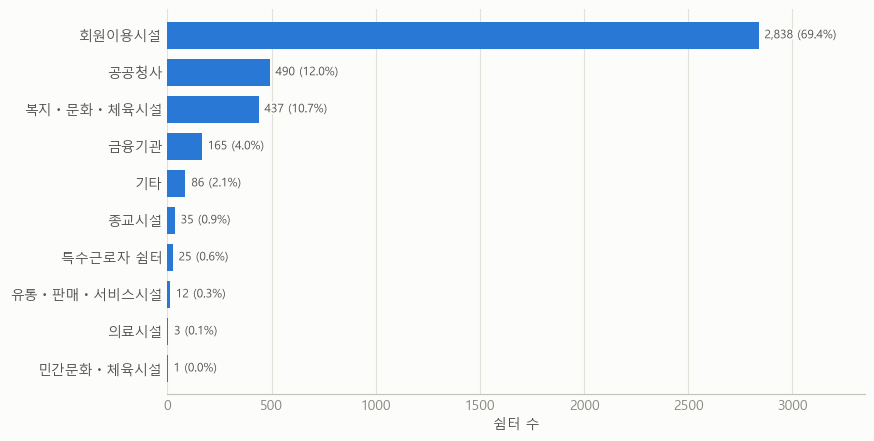

In [15]:
kind = shelter["시설구분2"].astype(str).str.replace("?", "ㆍ", regex=False).value_counts()
kind_pct = kind / kind.sum() * 100

fig, ax = plt.subplots(figsize=(9, 5))
barh(ax, kind, labels={k: f"{kind[k]:,} ({kind_pct[k]:.1f}%)" for k in kind.index})
ax.set_xlim(0, kind.max() * 1.18)
ax.set_xlabel("쉼터 수")
save(fig, "07_쉼터_유형.png")
plt.show()

## 8. 자치구별 60대 이상 비율

전체 유동인구가 많은 구와 고령 유동인구 비중이 높은 구는 다를 수 있다.
비율은 분자와 분모를 같은 기준으로 맞추려고 성별ㆍ연령 열(하루 전체)로 계산한다. 9~18시 기준인 `weight`는 쓰지 않는다.

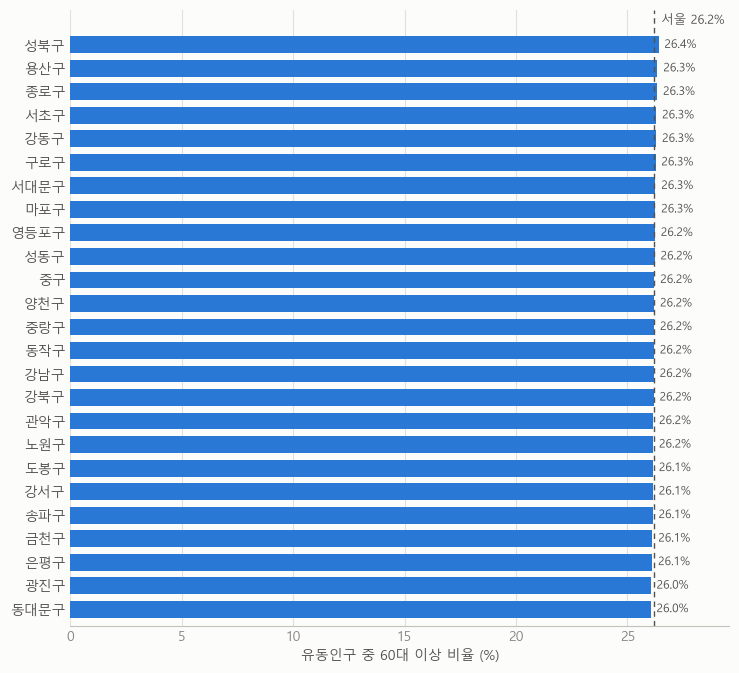

In [16]:
seoul_share = gu_tab["유동인구_60대이상_전일"].sum() / gu_tab["유동인구_전체"].sum() * 100

fig, ax = plt.subplots(figsize=(8.5, 8))
barh(ax, gu_tab["60대이상_비율_pct"].sort_values(ascending=False), fmt="{:.1f}%",
     avg=seoul_share, avg_label=f"서울 {seoul_share:.1f}%")
ax.set_xlabel("유동인구 중 60대 이상 비율 (%)")
save(fig, "08_자치구별_고령비율.png")
plt.show()

## 9. 후보시설 현황

신규 쉼터 후보가 어떤 시설이고 어느 구에 많은지 본다. 사각지대가 큰 구에 후보가 적으면 모형이 고를 자리가 없다.

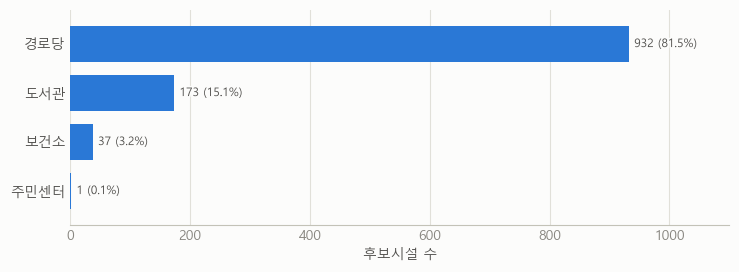

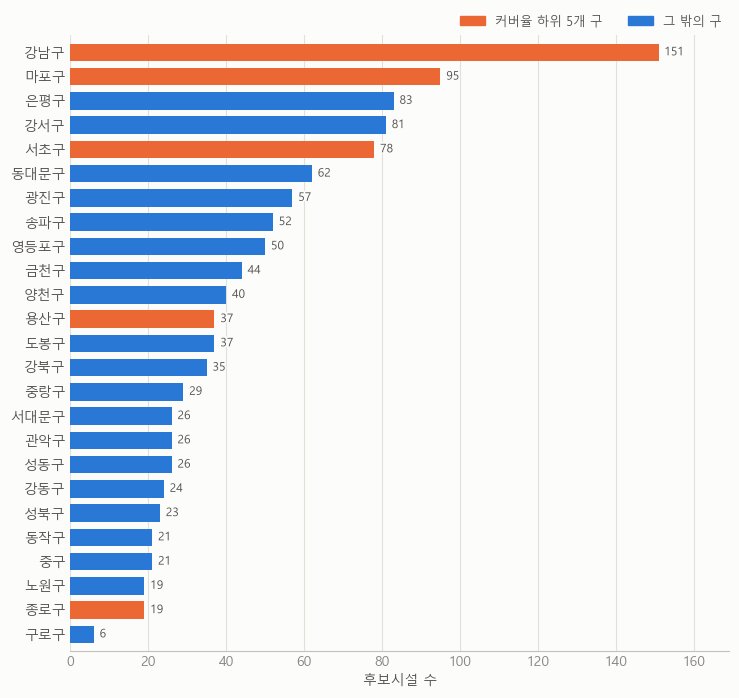

In [17]:
cand_kind = cand["시설유형"].astype(str).str.split("(").str[0].str.split("/").str[0].value_counts()
cand_gu = gu_tab["후보시설수"].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 2.8))
barh(ax, cand_kind, labels={k: f"{v:,} ({v / len(cand) * 100:.1f}%)" for k, v in cand_kind.items()})
ax.set_xlim(0, cand_kind.max() * 1.18)
ax.set_xlabel("후보시설 수")
save(fig, "09_후보시설_유형.png")
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 8))
barh(ax, cand_gu, highlight=low5_cov, fmt="{:,.0f}")
legend_top(ax, [Patch(color=ORANGE, label="커버율 하위 5개 구"), Patch(color=BLUE, label="그 밖의 구")])
ax.set_xlabel("후보시설 수")
save(fig, "09_자치구별_후보시설.png")
plt.show()

## 실제 자료로 돌릴 때

- `SAFE_ZONE = True`로 바꾸고 `FLOW_PATH`, `INPUT`을 확인한다. 유동인구는 7~9월을 합친 서울 전체 파일 하나다. `STD_YM` 열은 없어도 된다.
- 60대 이상 수요는 `weight` 열(9~18시)이다. 다른 열을 쓰려면 `WEIGHT_COL`만 바꾼다. 8번 고령 비율만 성별ㆍ연령 열(하루 전체)로 계산한다.
- 반입할 파일은 이 노트북과 `SeoulBoundary` 다섯 개(.shp, .shx, .dbf, .prj, .cpg), `SeoulCoolingCenter.csv`, `SeoulCandidateFacility.csv`다.
- 거리는 전부 직선거리다. 보고서에 넣을 커버율은 `서울_입지분석.ipynb`의 보행 네트워크 거리로 다시 계산한 값을 쓴다.
- 5번과 6번의 유동인구는 전체 연령이다. 60대 이상의 시간대, 요일 분포는 자료에 없다. 1절 출력의 "60대 이상 수요" 줄이 `weight 열`인지 먼저 확인한다.
- 2번과 3번 지도와 상위 10곳 표는 500m 구획 단위 집계다. 반출이 되는지 안심구역 담당자에게 확인한다.